# Slot tilt consistency — is there one shared decimal tilt per block?

The framework under test (from the discussion):

- Q1 established the first factor: per-anchor fraud rates in the low
  blocks are stable (small CIs).
- The hoped-for factorization: **P(fraud | anchor, slot) ~ P(fraud |
  anchor) x g(slot)** — one shared decimal tilt `g`, independent of the
  anchor inside the block. The Q3 pooled lift curve is the estimate of
  `g` (risk: alternating tilt, permutation p = 0.010; velocity: p =
  0.075).
- Open question 1: is the raw P(fraud | slot) itself consistent? Caveat
  it carries: a slot's marginal rate mixes the slot's own effect with
  *which anchors' rows sit in that slot* (block anchor rates span 4x).
- Open question 2: does `g` reproduce across independent samples
  (folds)?
- Open question 3: is one shared tilt enough for every anchor, or do
  individual anchors deviate from it beyond noise? (This separates
  "per-anchor cell rates are just sampling noise" from "there is real
  anchor-specific slot structure".)

Scope: same as Q3 — velocity anchors <= 40, risk anchors <= 55, anchors
with >= 50 frauds. Same frozen unified folds.

Views:

1. **The raw objects**: P(slot), P(slot | fraud), P(slot | clean) as
   shares, plus the marginal P(fraud | slot) with bootstrap CI against
   the block rate. Shows both the fill lumpiness and the composition
   confound.
2. **Fold consistency of the tilt**: g estimated separately in each of
   the 5 folds (each fold: its own per-anchor rates, its own lift);
   five thin curves against the pooled curve with CI.
3. **Anchor commonality**: fit one shared tilt g; compute each anchor's
   deviation from it; compare with deviations of data *simulated from
   that exact tilt*. If real deviations look like simulated ones, the
   shared tilt explains every anchor (per-anchor mess = sampling noise).
   If real deviations run larger, anchor-specific slot structure exists.

Interpretation deliberately deferred, as in Q1/Q3.

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ccf_ml.cross_validation.constants import ID_COLUMN, TARGET_COLUMN
from ccf_ml.file_utils import get_script_plot_dir, get_train_csv_path
from ccf_ml.region_modeling import load_alarm_profile_stratified_cv

BLOCKS = {"velocity_score": 40, "merchant_risk_score": 55}
MIN_FRAUDS = 50
SLOTS = np.arange(10)
B = 200
N_SIM = 200
rng = np.random.default_rng(42)

train = pd.read_csv(get_train_csv_path())
y = train[TARGET_COLUMN].to_numpy(dtype=bool)

cv = load_alarm_profile_stratified_cv()
ids = train[ID_COLUMN].to_numpy(dtype=np.int64)
fold_of = np.full(len(train), -1, dtype=np.int64)
pos_by_id = np.full(int(ids.max()) + 1, -1, dtype=np.int64)
pos_by_id[ids] = np.arange(len(ids))
for fold in cv.folds:
    for record_id in fold.val_ids:
        fold_of[pos_by_id[int(record_id)]] = fold.fold_id
assert (fold_of >= 0).all()

anchors = {c: np.floor(train[c].to_numpy(dtype=np.float64)).astype(np.int64) for c in BLOCKS}
slots = {c: np.rint((train[c].to_numpy(dtype=np.float64) - anchors[c]) * 10).astype(np.int64) for c in BLOCKS}

plot_dir = get_script_plot_dir("slot_tilt_stability", section="tilt", group="numerical_grid_structure")

block_frames = {}
for column, bound in BLOCKS.items():
    keep = anchors[column] <= bound
    block_frames[column] = pd.DataFrame(
        {"anchor": anchors[column][keep], "slot": slots[column][keep],
         "y": y[keep], "fold": fold_of[keep]}
    )
    used = block_frames[column].groupby("anchor")["y"].agg(frauds="sum", rows="size")
    used = used[used["frauds"] >= MIN_FRAUDS]
    block_frames[column + "::used_index"] = used.index
    print(
        f"{column:22s} block 0..{bound:2d} | used anchors: {len(used):2d} | "
        f"rows {int(used['rows'].sum()):7d} | frauds {int(used['frauds'].sum()):5d}"
    )

velocity_score         block 0..40 | used anchors: 35 | rows  592567 | frauds 10274
merchant_risk_score    block 0..55 | used anchors: 33 | rows  545952 | frauds  8761


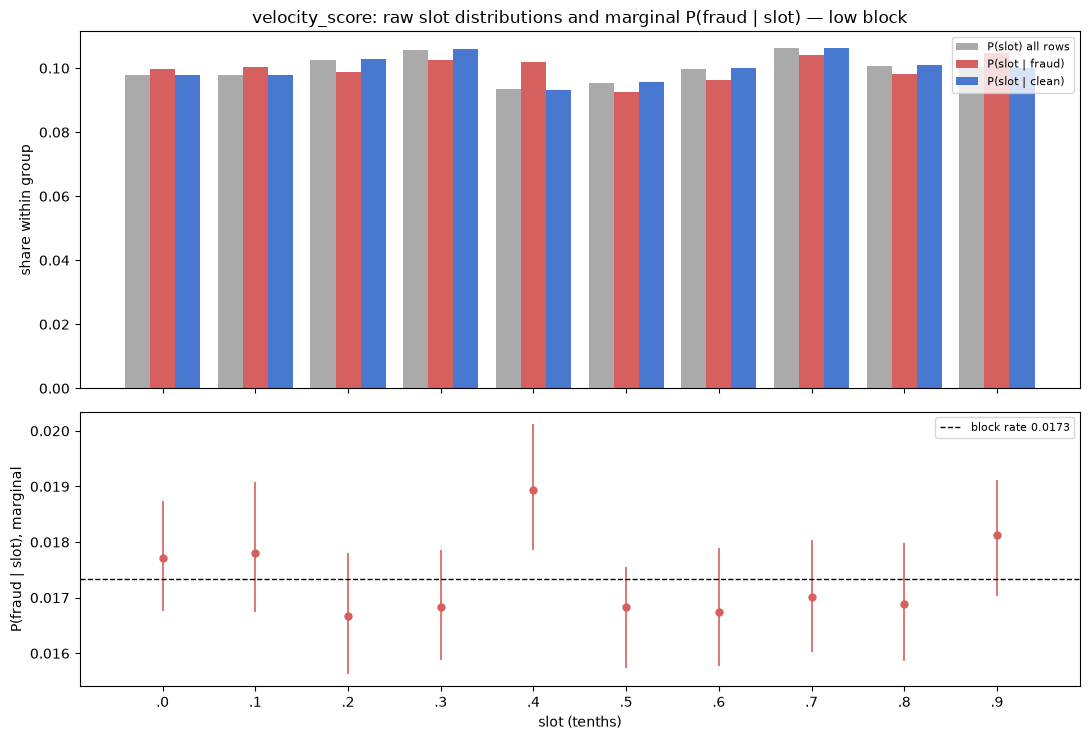

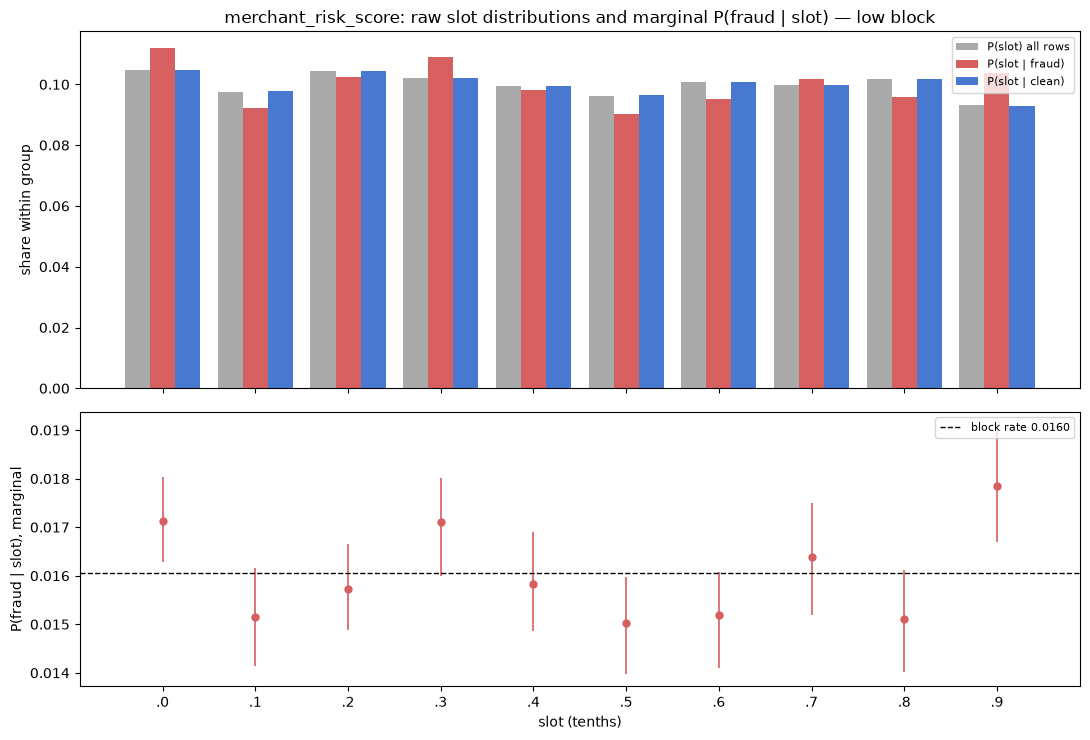

In [2]:
# View 1: the raw objects — P(slot), P(slot | fraud), P(slot | clean), P(fraud | slot)
for column in BLOCKS:
    frame = block_frames[column]
    used_idx = block_frames[column + "::used_index"]
    sub = frame[frame["anchor"].isin(used_idx)]
    n_s = sub.groupby("slot")["y"].size().reindex(SLOTS, fill_value=0)
    f_s = sub.groupby("slot")["y"].sum().reindex(SLOTS, fill_value=0)
    rate_s = f_s / n_s
    block_rate = f_s.sum() / n_s.sum()
    draws = rng.binomial(n_s.to_numpy()[:, None], rate_s.to_numpy()[:, None], size=(10, B)) / n_s.to_numpy()[:, None]
    lo, hi = np.percentile(draws, [2.5, 97.5], axis=1)

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]}
    )
    width = 0.27
    ax_top.bar(SLOTS - width, n_s / n_s.sum(), width=width, color="#aaaaaa", label="P(slot) all rows")
    ax_top.bar(SLOTS, f_s / f_s.sum(), width=width, color="#d65f5f", label="P(slot | fraud)")
    ax_top.bar(SLOTS + width, (n_s - f_s) / (n_s - f_s).sum(), width=width, color="#4878d0", label="P(slot | clean)")
    ax_top.set_ylabel("share within group")
    ax_top.legend(fontsize=8)
    ax_top.set_title(f"{column}: raw slot distributions and marginal P(fraud | slot) — low block")

    ax_bot.errorbar(
        SLOTS, rate_s, yerr=np.vstack([np.clip(rate_s - lo, 0, None), np.clip(hi - rate_s, 0, None)]),
        fmt="o", ms=5, lw=1.2, color="#d65f5f", ecolor="#d65f5f",
    )
    ax_bot.axhline(block_rate, color="black", lw=1, ls="--", label=f"block rate {block_rate:.4f}")
    ax_bot.set_ylabel("P(fraud | slot), marginal")
    ax_bot.set_xlabel("slot (tenths)")
    ax_bot.set_xticks(SLOTS)
    ax_bot.set_xticklabels([f".{i}" for i in SLOTS])
    ax_bot.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(plot_dir / f"{column}_raw_slot_objects.png", dpi=110)
    plt.show()

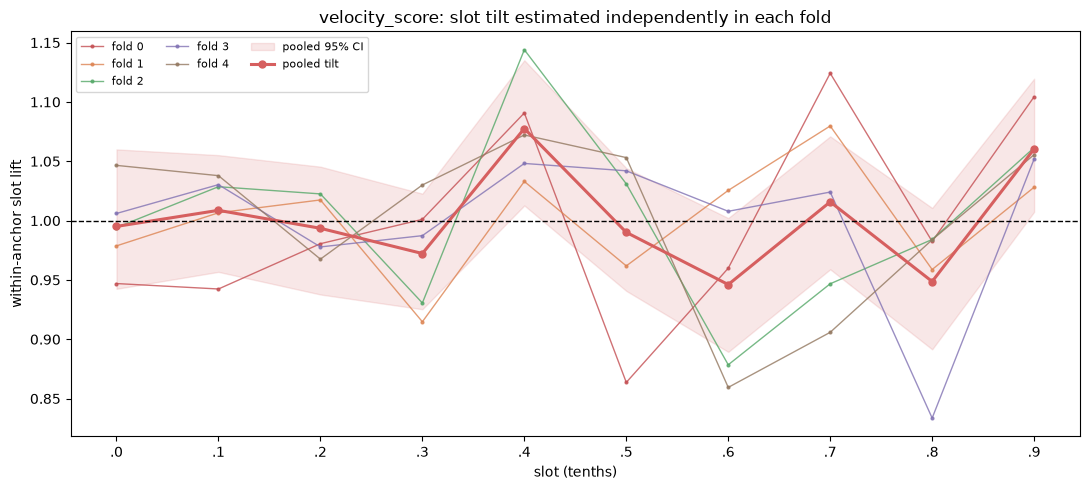

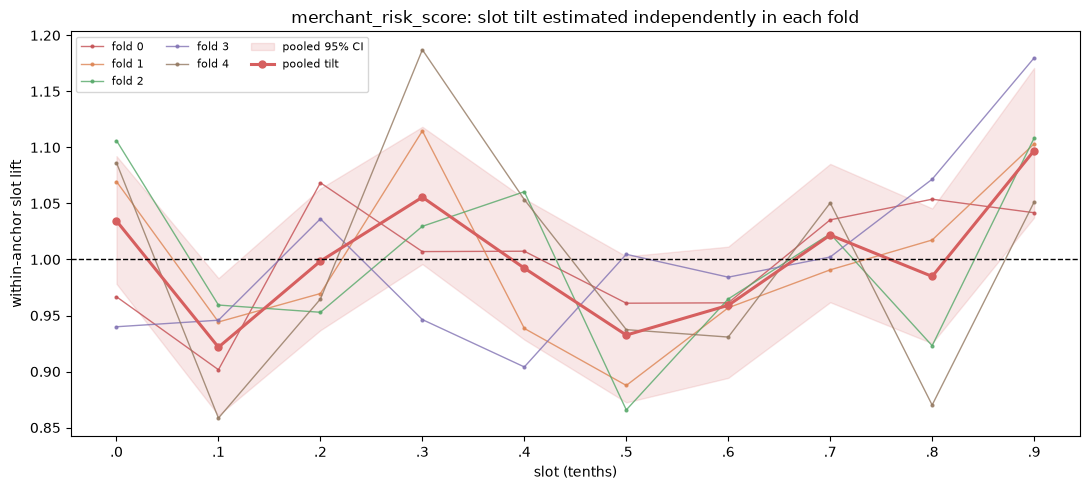

In [3]:
# View 2: fold consistency of the tilt — g estimated independently per fold
fold_tilts = {}
for column in BLOCKS:
    frame = block_frames[column]
    used_idx = block_frames[column + "::used_index"]
    sub = frame[frame["anchor"].isin(used_idx)]

    curves = {}
    for fold_id in range(cv.n_splits):
        ff = sub[sub["fold"] == fold_id]
        cell = ff.groupby(["anchor", "slot"])["y"].agg(fraud="sum", rows="size")
        rate_a = ff.groupby("anchor")["y"].mean()
        n_as = cell["rows"].unstack("slot").reindex(columns=SLOTS).fillna(0)
        f_as = cell["fraud"].unstack("slot").reindex(columns=SLOTS).fillna(0)
        exp = (n_as.mul(rate_a, axis=0)).sum(axis=0)
        curves[fold_id] = f_as.sum(axis=0) / exp

    # pooled tilt + bootstrap CI (same estimator as Q3, recomputed here)
    cell = sub.groupby(["anchor", "slot"])["y"].agg(fraud="sum", rows="size")
    rate_a = sub.groupby("anchor")["y"].mean()
    n_as = cell["rows"].unstack("slot").reindex(index=used_idx, columns=SLOTS).fillna(0).to_numpy(np.int64)
    f_as = cell["fraud"].unstack("slot").reindex(index=used_idx, columns=SLOTS).fillna(0).to_numpy(np.int64)
    exp = (n_as * rate_a.reindex(used_idx).to_numpy()[:, None]).sum(axis=0)
    pooled = f_as.sum(axis=0) / exp
    draws = rng.binomial(n_as[:, :, None], (f_as / n_as)[:, :, None], size=(len(used_idx), 10, B))
    f_star = draws.sum(axis=0)
    fraud_star_anchor = draws.sum(axis=1)          # (A, B)
    rate_star = fraud_star_anchor / n_as.sum(axis=1)[:, None]
    exp_star = (n_as[:, :, None] * rate_star[:, None, :]).sum(axis=0)
    lift_star = f_star / exp_star
    lo, hi = np.percentile(lift_star, [2.5, 97.5], axis=1)
    fold_tilts[column] = {"curves": pd.DataFrame(curves), "pooled": pooled, "lo": lo, "hi": hi}

    fig, ax = plt.subplots(figsize=(11, 5))
    shades = ["#c44e52", "#dd8452", "#55a868", "#8172b3", "#937860"]
    for i, (fold_id, curve) in enumerate(curves.items()):
        ax.plot(SLOTS, curve.to_numpy(), lw=1, alpha=0.8, color=shades[i], marker=".", ms=4, label=f"fold {fold_id}")
    ax.fill_between(SLOTS, lo, hi, color="#d65f5f", alpha=0.15, label="pooled 95% CI")
    ax.plot(SLOTS, pooled, lw=2.2, color="#d65f5f", marker="o", ms=5, label="pooled tilt")
    ax.axhline(1.0, color="black", lw=1, ls="--")
    ax.set_xticks(SLOTS)
    ax.set_xticklabels([f".{i}" for i in SLOTS])
    ax.set_xlabel("slot (tenths)")
    ax.set_ylabel("within-anchor slot lift")
    ax.set_title(f"{column}: slot tilt estimated independently in each fold")
    ax.legend(fontsize=8, ncol=3)
    fig.tight_layout()
    fig.savefig(plot_dir / f"{column}_fold_tilts.png", dpi=110)
    plt.show()

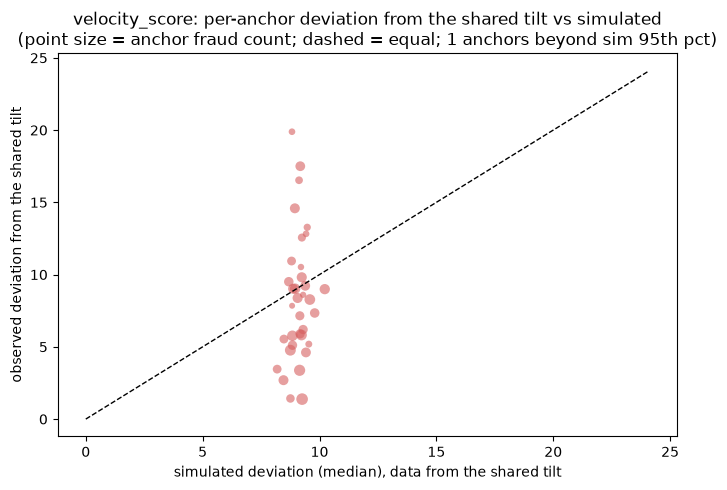

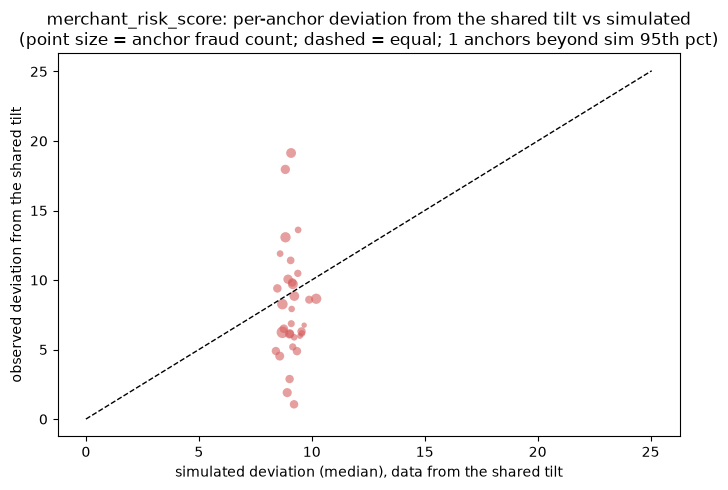

,column,anchors,observed chi2 (total),simulated chi2 median (total),ratio obs/sim,anchors beyond sim 95th pct
0,velocity_score,35,293.0,339.9,0.86,1/35 (5% expected)
1,merchant_risk_score,33,267.1,324.6,0.82,1/33 (5% expected)


In [4]:
# View 3: anchor commonality — does one shared tilt explain every anchor?
commonality_rows = []
for column in BLOCKS:
    frame = block_frames[column]
    used_idx = block_frames[column + "::used_index"]
    sub = frame[frame["anchor"].isin(used_idx)]
    cell = sub.groupby(["anchor", "slot"])["y"].agg(fraud="sum", rows="size")
    rate_a = sub.groupby("anchor")["y"].mean()
    n_as = cell["rows"].unstack("slot").reindex(index=used_idx, columns=SLOTS).fillna(0).to_numpy(np.int64)
    f_as = cell["fraud"].unstack("slot").reindex(index=used_idx, columns=SLOTS).fillna(0).to_numpy(np.int64)
    rate_a = rate_a.reindex(used_idx).to_numpy()

    g = np.asarray(fold_tilts[column]["pooled"])
    n_a = n_as.sum(axis=1)
    # under the shared tilt: P(fraud | anchor, slot) = rate_a * g_s / Z_a
    Z_a = (n_as * g[None, :]).sum(axis=1) / n_a
    p_as = rate_a[:, None] * g[None, :] / Z_a[:, None]
    mu_as = n_as * p_as

    with np.errstate(divide="ignore", invalid="ignore"):
        chi_a = np.nansum(np.where(mu_as > 0, (f_as - mu_as) ** 2 / mu_as, 0.0), axis=1)

    # simulate data from the shared-tilt model itself, same row counts
    sim_chi = np.empty((N_SIM, len(used_idx)))
    for b in range(N_SIM):
        f_sim = rng.binomial(n_as, p_as)
        with np.errstate(divide="ignore", invalid="ignore"):
            sim_chi[b] = np.nansum(np.where(mu_as > 0, (f_sim - mu_as) ** 2 / mu_as, 0.0), axis=1)
    thresh = np.percentile(sim_chi, 95, axis=0)
    exceed = chi_a > thresh

    commonality_rows.append({
        "column": column,
        "anchors": len(used_idx),
        "observed chi2 (total)": round(float(chi_a.sum()), 1),
        "simulated chi2 median (total)": round(float(np.median(sim_chi.sum(axis=1))), 1),
        "ratio obs/sim": round(float(chi_a.sum() / np.median(sim_chi.sum(axis=1))), 2),
        "anchors beyond sim 95th pct": f"{int(exceed.sum())}/{len(used_idx)} (5% expected)",
    })

    fig, ax = plt.subplots(figsize=(7, 5))
    sizes = 10 + 60 * (f_as.sum(axis=1) / f_as.sum(axis=1).max())
    ax.scatter(np.median(sim_chi, axis=0), chi_a, s=sizes, alpha=0.6, color="#d65f5f", edgecolor="none")
    lims = [0, max(np.percentile(sim_chi, 99), chi_a.max()) * 1.05]
    ax.plot(lims, lims, color="black", lw=1, ls="--")
    ax.set_xlabel("simulated deviation (median), data from the shared tilt")
    ax.set_ylabel("observed deviation from the shared tilt")
    ax.set_title(
        f"{column}: per-anchor deviation from the shared tilt vs simulated\n"
        f"(point size = anchor fraud count; dashed = equal; {int(exceed.sum())} anchors beyond sim 95th pct)"
    )
    fig.tight_layout()
    fig.savefig(plot_dir / f"{column}_commonality.png", dpi=110)
    plt.show()
pd.DataFrame(commonality_rows)

In [5]:
# descriptive summary only - no conclusions yet
rows = []
for column in BLOCKS:
    t = fold_tilts[column]
    curves = t["curves"]
    spread = (curves.max(axis=1) - curves.min(axis=1)).mean()
    ci_width = (t["hi"] - t["lo"]).mean()
    perm = next(r for r in commonality_rows if r["column"] == column)
    rows.append({
        "column": column,
        "mean fold spread of tilt": round(float(spread), 3),
        "mean pooled CI width": round(float(ci_width), 3),
        "fold spread / CI width": round(float(spread / ci_width), 2),
        "anchors beyond sim 95th": perm["anchors beyond sim 95th pct"],
        "obs/sim chi2 ratio": perm["ratio obs/sim"],
    })
pd.DataFrame(rows)

,column,mean fold spread of tilt,mean pooled CI width,fold spread / CI width,anchors beyond sim 95th,obs/sim chi2 ratio
0,velocity_score,0.128,0.110,1.16,1/35 (5% expected),0.86
1,merchant_risk_score,0.137,0.124,1.11,1/33 (5% expected),0.82


## Interpretation

Written 2026-11-22, after review; the factorization verdict this notebook was built for.

- The framework P(fraud | anchor, slot) ~ P(fraud | anchor) x g(slot) HOLDS
  in the low blocks, on all three legs: factor 1 is stable (Q1); g
  replicates across the five folds (fold spread only ~1.1x the pooled CI
  width); and ONE shared g fits every anchor (per-anchor deviations from
  the shared tilt are noise-sized, obs/sim 0.82-0.86, only 1 anchor per
  column beyond the simulated 95th percentile).
- So the "oscillating" per-anchor cell rates from the Q3 small multiples
  are sampling noise, not anchor-specific slot structure.
- Caveat: the reference simulations use plain binomial draws while the
  target-stratified folds make real label allocation slightly more regular
  than binomial - ratios below 1 carry no information; the test only
  speaks when observed deviations EXCEED simulated ones.
- Consequence, tested the same day: the common-tilt feature (atilt,
  anchor_v2t) added +0.00006 - nothing beyond arate10. The factorization is
  a correct description of the generator but not a new feature lever.